# 05 - Evaluación

## Objetivo de este cuaderno

Comparamos los tres modelos con las mismas métricas sobre el conjunto de prueba y elegimos el mejor.

- **Lee:** modelos de models/ y test de data/processed/
- **Guarda:** tabla de resultados y figuras en outputs/

### Importar librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

## 1. Tabla comparativa de los tres modelos

Cargamos las métricas que guardamos en el cuaderno de modelado para cada modelo. Así partimos de los mismos resultados sin volver a entrenar nada.

In [2]:
metricas_lineal = pd.read_csv('../outputs/metricas_lineal.csv')
metricas_rf = pd.read_csv('../outputs/metricas_random_forest.csv')
metricas_xgb = pd.read_csv('../outputs/metricas_xgboost.csv')

Añadimos una columna con el nombre del modelo y unimos las tres tablas en una sola.

In [3]:
metricas_lineal['modelo'] = 'Regresión lineal'
metricas_rf['modelo'] = 'Random Forest'
metricas_xgb['modelo'] = 'XGBoost'

metricas = pd.concat([metricas_lineal, metricas_rf, metricas_xgb])
metricas

,conjunto,MAE (€),MAPE (%),RMSE (€),R2 (log),modelo
0,train,2619.698594,16.790716,5110.705636,0.906384,Regresión lineal
1,test,2664.473926,16.803014,5301.915327,0.907277,Regresión lineal
0,train,669.900487,4.568741,1229.110915,0.991532,Random Forest
1,test,1816.341555,12.594596,3372.336143,0.940308,Random Forest
0,train,1498.704616,10.151422,2380.222303,0.964751,XGBoost
1,test,1853.691949,12.717755,3248.199588,0.942088,XGBoost


Nos quedamos con los resultados sobre test, que son los que miden cómo funciona cada modelo con coches que no ha visto.

In [4]:
tabla_test = metricas[metricas['conjunto'] == 'test']
tabla_test = tabla_test.drop(columns='conjunto')
tabla_test = tabla_test.set_index('modelo')
tabla_test.round(3)

,MAE (€),MAPE (%),RMSE (€),R2 (log)
modelo,,,,
Regresión lineal,2664.474,16.803,5301.915,0.907
Random Forest,1816.342,12.595,3372.336,0.940
XGBoost,1853.692,12.718,3248.200,0.942


Comparamos también el MAE de train y de test para ver cuánto se aleja cada modelo de los datos con los que aprendió.

In [5]:
mae_train = metricas[metricas['conjunto'] == 'train'].set_index('modelo')['MAE (€)']
mae_test = metricas[metricas['conjunto'] == 'test'].set_index('modelo')['MAE (€)']

diferencia = pd.DataFrame({'MAE train (€)': mae_train, 'MAE test (€)': mae_test})
diferencia['Diferencia (€)'] = diferencia['MAE test (€)'] - diferencia['MAE train (€)']
diferencia.round(0)

,MAE train (€),MAE test (€),Diferencia (€)
modelo,,,
Regresión lineal,2620.0,2664.0,45.0
Random Forest,670.0,1816.0,1146.0
XGBoost,1499.0,1854.0,355.0


### Observaciones de la tabla comparativa

- La regresión lineal queda claramente por detrás en todas las métricas, así que la elección está entre Random Forest y XGBoost.
- Random Forest gana por poco en MAE (1.816 € frente a 1.854 €) y en MAPE (12,6 % frente a 12,7 %).
- XGBoost gana en RMSE (3.248 € frente a 3.372 €), es decir, comete menos errores grandes.
- Random Forest tiene un MAE de 670 € en train y 1.816 € en test, una diferencia de unos 1.150 €. XGBoost pasa de 1.499 € a 1.854 €, unos 350 €. XGBoost generaliza mejor.
- Con diferencias tan pequeñas, las métricas generales no bastan para elegir. Hace falta mirar los errores desde el punto de vista del negocio.

Con esto descartamos la regresión lineal. A partir de aquí comparamos solo Random Forest y XGBoost.

## 2. Cargar los modelos y los datos de prueba

En el cuaderno de modelado guardamos cada modelo entrenado con la librería joblib. joblib.dump escribe el modelo en un archivo y joblib.load lo recupera tal cual, listo para predecir. Así no hace falta volver a entrenar en cada cuaderno, y es también la forma de reutilizar el modelo fuera del proyecto, por ejemplo en una aplicación.

In [6]:
rf = joblib.load('../models/random_forest.joblib')
xgb = joblib.load('../models/xgboost.joblib')

Cargamos el conjunto de prueba sin escalar, que es el que usan los dos modelos de árboles.

In [7]:
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv')['price']
print(X_test.shape, y_test.shape)

(8123, 26) (8123,)


Los modelos predicen el logaritmo del precio, así que deshacemos el logaritmo con np.exp para trabajar en euros.

In [8]:
precio_real = np.exp(y_test)
pred_rf = np.exp(rf.predict(X_test))
pred_xgb = np.exp(xgb.predict(X_test))

Comprobamos que el MAE coincide con el del cuaderno de modelado.

In [9]:
print('MAE Random Forest:', round(mean_absolute_error(precio_real, pred_rf)))
print('MAE XGBoost:', round(mean_absolute_error(precio_real, pred_xgb)))

MAE Random Forest: 1816
MAE XGBoost: 1854


## 3. Errores por sobrevaloración

Para el concesionario no pesa igual equivocarse hacia arriba que hacia abajo. Si el modelo estima un precio mayor que el real, ofreceríamos de más por el coche y perderíamos dinero al venderlo. Si lo estima por debajo, la oferta sería baja y como mucho perderíamos la compra.

Calculamos el error de cada coche como predicción menos precio real. Un error positivo significa que el modelo sobrevalora el coche.

In [10]:
errores = pd.DataFrame({'real': precio_real, 'error_rf': pred_rf - precio_real, 'error_xgb': pred_xgb - precio_real})
errores.head()

,real,error_rf,error_xgb
0,4000.0,-1488.390225,-1275.242187
1,29900.0,-3497.788525,-3476.558594
2,22999.0,3556.629001,2598.072266
3,7999.0,1761.497572,2305.455078
4,7890.0,-689.614223,-1089.114258


Para cada modelo calculamos qué porcentaje de coches sobrevalora, cuánto sobrevalora de media y cuántos euros suman esas sobrevaloraciones en todo el conjunto de prueba.

In [11]:
sobre_rf = errores[errores['error_rf'] > 0]['error_rf']
sobre_xgb = errores[errores['error_xgb'] > 0]['error_xgb']

sobrevaloracion = pd.DataFrame({
    'Coches sobrevalorados (%)': [len(sobre_rf) / len(errores) * 100, len(sobre_xgb) / len(errores) * 100],
    'Sobrevaloración media (€)': [sobre_rf.mean(), sobre_xgb.mean()],
    'Sobrevaloración total (€)': [sobre_rf.sum(), sobre_xgb.sum()]
}, index=['Random Forest', 'XGBoost'])
sobrevaloracion.round(1)

,Coches sobrevalorados (%),Sobrevaloración media (€),Sobrevaloración total (€)
Random Forest,49.9,1536.6,6232483.1
XGBoost,50.1,1623.6,6609562.5


### Observaciones de la sobrevaloración

- Los dos modelos sobrevaloran más o menos la mitad de los coches (49,9 % el Random Forest y 50,1 % el XGBoost), así que ninguno tiende claramente a pasarse.
- Cuando se pasa, el Random Forest lo hace de media en 1.537 € y el XGBoost en 1.624 €.
- En total, en los 8.123 coches de prueba, el Random Forest suma unos 6,23 millones de euros sobrevalorados y el XGBoost unos 6,61 millones, alrededor de 380.000 € más.
- Con este criterio de negocio el Random Forest es el que menos dinero pondría en riesgo.

### Cómo se protege el negocio de este error

- Sin ningún margen, comprar coches al precio que estima el modelo sería inasumible: la mitad de las compras tendrían un sobrecoste medio de unos 1.500 €.
- La oferta al vendedor no es el precio estimado, sino el precio estimado × (1 − margen) − costes de preparación. Con un margen del 15 %, en un coche de 13.000 € quedan casi 2.000 € de colchón, y buena parte de las sobrevaloraciones caben dentro.
- La otra mitad de los coches el modelo los infravalora, con un error medio de unos 2.100 €. En esas compras el beneficio es mayor de lo previsto, o como mucho se pierde la operación.
- Por eso no reentrenamos los modelos para que tiendan a infravalorar. La protección frente al error la da el margen, y lo que hay que medir es qué porcentaje de coches queda dentro de él y qué margen mínimo hace falta para no perder dinero.

## 4. ¿En qué coches falla más cada modelo?

Para ver dónde se equivocan los modelos calculamos el error porcentual de cada coche, es decir, el error en euros dividido entre su precio real. Así un error de 1.000 € pesa más en un coche de 5.000 € que en uno de 40.000 €.

In [12]:
errores['error_pct_rf'] = abs(errores['error_rf']) / errores['real'] * 100
errores['error_pct_xgb'] = abs(errores['error_xgb']) / errores['real'] * 100
errores['age'] = X_test['age']

Agrupamos los coches en rangos de precio con pd.cut, que reparte una columna numérica en intervalos que le indicamos con bins y les pone los nombres de labels.

In [13]:
errores['rango_precio'] = pd.cut(errores['real'], bins=[0, 5000, 10000, 20000, 40000, 60000, 100000, 10000000], labels=['< 5.000', '5.000 - 10.000', '10.000 - 20.000', '20.000 - 40.000', '40.000 - 60.000', '60.000 - 100.000', '> 100.000'])

error_por_precio = errores.groupby('rango_precio', observed=True)[['error_pct_rf', 'error_pct_xgb']].mean()
error_por_precio['coches'] = errores['rango_precio'].value_counts()
error_por_precio.round(1)

,error_pct_rf,error_pct_xgb,coches
rango_precio,,,
< 5.000,29.4,28.1,871
5.000 - 10.000,13.6,13.5,1833
10.000 - 20.000,9.6,10.1,3124
20.000 - 40.000,8.9,9.3,1869
40.000 - 60.000,10.7,11.0,294
60.000 - 100.000,15.4,14.2,132


Cómo leer la tabla: error_pct_rf y error_pct_xgb son el error porcentual medio de cada modelo en ese tramo, es decir, lo que se equivoca el modelo en euros dividido entre el precio real del coche, en promedio. Por ejemplo, un 29,4 en el tramo de menos de 5.000 € significa que el Random Forest falla de media un 29,4 % del precio de esos coches. La columna coches indica cuántos coches del conjunto de prueba hay en cada tramo. La tabla por antigüedad se lee igual.

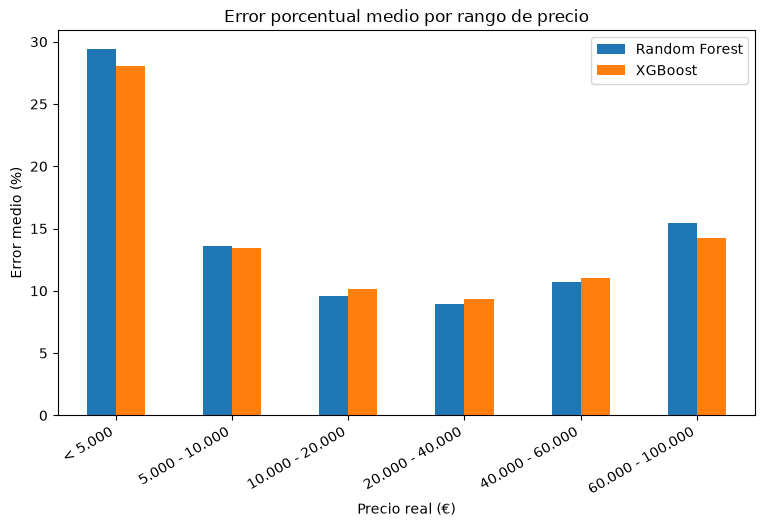

In [14]:
error_por_precio[['error_pct_rf', 'error_pct_xgb']].plot(kind='bar', figsize=(9, 5))
plt.title('Error porcentual medio por rango de precio')
plt.xlabel('Precio real (€)')
plt.ylabel('Error medio (%)')
plt.legend(['Random Forest', 'XGBoost'])
plt.xticks(rotation=30, ha='right')
plt.savefig('../outputs/figures/16_error_por_precio.png', bbox_inches='tight')
plt.show()

Hacemos lo mismo con la antigüedad del coche.

In [15]:
errores['rango_edad'] = pd.cut(errores['age'], bins=[-1, 3, 7, 12, 100], labels=['0 - 3 años', '4 - 7 años', '8 - 12 años', 'Más de 12 años'])

error_por_edad = errores.groupby('rango_edad', observed=True)[['error_pct_rf', 'error_pct_xgb']].mean()
error_por_edad['coches'] = errores['rango_edad'].value_counts()
error_por_edad.round(1)

,error_pct_rf,error_pct_xgb,coches
rango_edad,,,
0 - 3 años,8.2,8.9,2577
4 - 7 años,10.3,10.6,2927
8 - 12 años,16.6,15.8,1465
Más de 12 años,23.2,22.7,1154


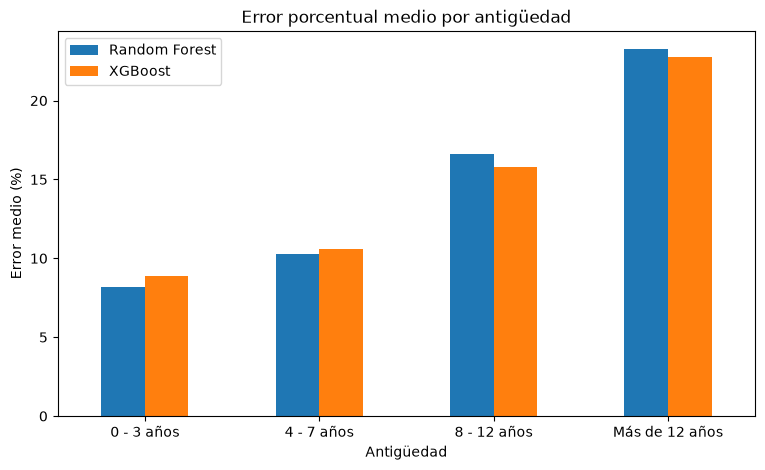

In [16]:
error_por_edad[['error_pct_rf', 'error_pct_xgb']].plot(kind='bar', figsize=(9, 5))
plt.title('Error porcentual medio por antigüedad')
plt.xlabel('Antigüedad')
plt.ylabel('Error medio (%)')
plt.legend(['Random Forest', 'XGBoost'])
plt.xticks(rotation=0)
plt.savefig('../outputs/figures/17_error_por_edad.png', bbox_inches='tight')
plt.show()

### Observaciones de dónde fallan los modelos

- Los dos modelos fallan en los mismos sitios y con errores muy parecidos.
- Por precio, el error se dispara en los coches de menos de 5.000 €, en torno al 28-29 %. Entre 10.000 y 40.000 € baja a un 9-10 %. En la gama media-alta, de 40.000 a 60.000 €, se mantiene en torno al 11 %, y en la alta gama, de 60.000 a 100.000 €, sube al 14-15 %, con solo 132 coches. En el conjunto de prueba no hay coches de más de 100.000 €.
- Por antigüedad, el error crece con los años: un 8-9 % en coches de hasta 3 años y más de un 22 % en los de más de 12.
- Los coches baratos y viejos son los más difíciles de tasar, porque su precio depende mucho del estado del coche, algo que no está en los datos.
- Random Forest acierta algo más en los coches de 10.000 a 40.000 € y en los más nuevos, que son el grueso del negocio. XGBoost es ligeramente mejor en los más baratos y en los de 8 a 12 años.

## 5. Elección del modelo

Guardamos la tabla comparativa de test en outputs/ para tenerla como referencia.

In [17]:
tabla_test.round(3).to_csv('../outputs/comparativa_modelos.csv')

### Modelo elegido: Random Forest

- La regresión lineal queda descartada por sus resultados claramente peores en todas las métricas.
- Random Forest y XGBoost están muy igualados en las métricas generales. Random Forest gana en MAE y MAPE y XGBoost en RMSE.
- Con el criterio de negocio, Random Forest pone menos dinero en riesgo: su sobrevaloración media es de 1.537 € frente a 1.624 €, unos 380.000 € menos en el conjunto de prueba.
- Random Forest también acierta más en los coches de 10.000 a 40.000 € y en los de hasta 3 años, que son el grueso de las compras de un concesionario.
- Como contrapartida, Random Forest se ajusta mucho más a los datos de entrenamiento (670 € de MAE en train frente a 1.816 € en test). Aun así, sus resultados en test, con coches que no ha visto, son los mejores para el negocio, que es lo que cuenta.
- XGBoost queda como alternativa válida, con resultados muy cercanos y un comportamiento más estable entre train y test.